<a href="https://colab.research.google.com/github/SaiLinHtet-KiRA/Big-Data-Analytics/blob/main/week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Part 1 — Start Google Colab and PySpark**

## **Step 1.1 — Install PySpark**

In [5]:
!pip -q install pyspark

# **Step 1.2 — Create a SparkSession**

In [6]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("CSC475Week10Lab")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 4.0.5


# **Part 2 — Upload and Load the Dataset**

## **Step 2.1 — Upload the CSV file**

In [7]:
from google.colab import files

uploaded = files.upload()

Saving sales_week10_lab.csv to sales_week10_lab.csv


## **Step 2.2 — Read the CSV into a Spark DataFrame**

In [8]:
df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("sales_week10_lab.csv")
)

df.show()
df.printSchema()

+--------+---------+-----------+--------+--------+----------+
|order_id|     city|   category| product|quantity|unit_price|
+--------+---------+-----------+--------+--------+----------+
|    1001|  Bangkok|Electronics|  Laptop|       1|   35000.0|
|    1002|  Bangkok|Accessories|   Mouse|       2|     500.0|
|    1003|ChiangMai|Electronics|  Laptop|       1|   34000.0|
|    1004|  Bangkok|Accessories|Keyboard|       1|    1500.0|
|    1005|   Phuket|       Food|  Coffee|       3|     120.0|
|    1006|ChiangMai|       Food|  Coffee|       2|     100.0|
|    1007|   Phuket|Electronics| Monitor|       1|    9000.0|
|    1008|  Bangkok|Electronics| Monitor|       2|    8500.0|
|    1009|ChiangMai|Accessories|   Mouse|       3|     450.0|
|    1010|   Phuket|Accessories|Keyboard|       2|    1400.0|
|    1011|  Bangkok|       Food|  Coffee|       5|     110.0|
|    1012|ChiangMai|Electronics| Monitor|       2|    8800.0|
+--------+---------+-----------+--------+--------+----------+

root
 |

## **Step 2.3 — Create the analytical variable total_value**

In [9]:
df = df.withColumn(
    "total_value",
    F.col("quantity") * F.col("unit_price")
)

df.select(
    "order_id", "city", "category", "product",
    "quantity", "unit_price", "total_value"
).show()

+--------+---------+-----------+--------+--------+----------+-----------+
|order_id|     city|   category| product|quantity|unit_price|total_value|
+--------+---------+-----------+--------+--------+----------+-----------+
|    1001|  Bangkok|Electronics|  Laptop|       1|   35000.0|    35000.0|
|    1002|  Bangkok|Accessories|   Mouse|       2|     500.0|     1000.0|
|    1003|ChiangMai|Electronics|  Laptop|       1|   34000.0|    34000.0|
|    1004|  Bangkok|Accessories|Keyboard|       1|    1500.0|     1500.0|
|    1005|   Phuket|       Food|  Coffee|       3|     120.0|      360.0|
|    1006|ChiangMai|       Food|  Coffee|       2|     100.0|      200.0|
|    1007|   Phuket|Electronics| Monitor|       1|    9000.0|     9000.0|
|    1008|  Bangkok|Electronics| Monitor|       2|    8500.0|    17000.0|
|    1009|ChiangMai|Accessories|   Mouse|       3|     450.0|     1350.0|
|    1010|   Phuket|Accessories|Keyboard|       2|    1400.0|     2800.0|
|    1011|  Bangkok|       Food|  Coff

# **Part 3 — Quick Descriptive Statistical Summary**

## **Step 3.1 — Use describe()**

In [10]:
df.select(
    "quantity",
    "unit_price",
    "total_value"
).describe().show()

+-------+------------------+------------------+------------------+
|summary|          quantity|        unit_price|       total_value|
+-------+------------------+------------------+------------------+
|  count|                12|                12|                12|
|   mean|2.0833333333333335|            8290.0|           10030.0|
| stddev| 1.164500152881315|12762.515426043567|13027.711024790753|
|    min|                 1|             100.0|             200.0|
|    max|                 5|           35000.0|           35000.0|
+-------+------------------+------------------+------------------+



## **Step 3.2 — Count the observations**

In [11]:
n = df.count()
print("Number of transactions:", n)

Number of transactions: 12


# **Part 4 — Central Tendency: Mean and Median**

## **Step 4.1 — Calculate the mean order value**

In [12]:
mean_row = df.select(
    F.mean("total_value").alias("mean_order_value")
)

mean_row.show()

+----------------+
|mean_order_value|
+----------------+
|         10030.0|
+----------------+



## **Step 4.2 — Calculate the median with approxQuantile()**

In [13]:
median = df.approxQuantile(
    "total_value",
    [0.5],
    0.0
)[0]

print("Median order value:", median)

Median order value: 1500.0


## **Step 4.3 — Compare mean and median**

In [14]:
mean_value = df.select(
    F.mean("total_value")
).first()[0]

print("Mean  :", mean_value)
print("Median:", median)
print("Difference:", mean_value - median)

Mean  : 10030.0
Median: 1500.0
Difference: 8530.0


# **Part 5 — Dispersion: Min, Max, Range, Variance, Standard Deviation**

## **Step 5.1 — Minimum, maximum, and range**

In [15]:
range_stats = df.select(
    F.min("total_value").alias("minimum"),
    F.max("total_value").alias("maximum"),
    (
        F.max("total_value") - F.min("total_value")
    ).alias("range")
)

range_stats.show()

+-------+-------+-------+
|minimum|maximum|  range|
+-------+-------+-------+
|  200.0|35000.0|34800.0|
+-------+-------+-------+



## **Step 5.2 — Variance and standard deviation**

In [16]:
dispersion = df.select(
    F.var_samp("total_value").alias("sample_variance"),
    F.stddev_samp("total_value").alias("sample_stddev")
)

dispersion.show()

+--------------------+------------------+
|     sample_variance|     sample_stddev|
+--------------------+------------------+
|1.6972125454545453E8|13027.711024790753|
+--------------------+------------------+



## **Step 5.3 — Build one statistical summary**

In [17]:
summary = df.select(
    F.count("*").alias("n"),
    F.mean("total_value").alias("mean"),
    F.stddev_samp("total_value").alias("stddev"),
    F.min("total_value").alias("min"),
    F.max("total_value").alias("max")
)

summary.show()

+---+-------+------------------+-----+-------+
|  n|   mean|            stddev|  min|    max|
+---+-------+------------------+-----+-------+
| 12|10030.0|13027.711024790753|200.0|35000.0|
+---+-------+------------------+-----+-------+



# **Part 6 — Quartiles and Percentiles**

## **Step 6.1 — Calculate Q1, Median, and Q3**

In [18]:
quantiles = df.approxQuantile(
    "total_value",
    [0.25, 0.50, 0.75],
    0.0
)

q1, q2, q3 = quantiles
print("Q1    :", q1)
print("Median:", q2)
print("Q3    :", q3)

Q1    : 550.0
Median: 1500.0
Q3    : 17000.0


## **Step 6.2 — Calculate the interquartile range (IQR)**

In [19]:
iqr = q3 - q1
print("IQR:", iqr)

IQR: 16450.0


# **Part 7 — Frequency Distributions**

## **Step 7.1 — Frequency by category**

In [20]:
category_frequency = (
    df
    .groupBy("category")
    .count()
    .orderBy(F.desc("count"))
)

category_frequency.show()

+-----------+-----+
|   category|count|
+-----------+-----+
|Electronics|    5|
|Accessories|    4|
|       Food|    3|
+-----------+-----+



## **Step 7.2 — Frequency by city**

In [21]:
city_frequency = (
    df
    .groupBy("city")
    .count()
    .orderBy(F.desc("count"))
)

city_frequency.show()

+---------+-----+
|     city|count|
+---------+-----+
|  Bangkok|    5|
|ChiangMai|    4|
|   Phuket|    3|
+---------+-----+



# Part 8 — Grouped Descriptive Statistics

## **Step 8.1 — Statistics by city**

In [22]:
city_stats = (
    df
    .groupBy("city")
    .agg(
        F.count("*").alias("transactions"),
        F.sum("total_value").alias("total_sales"),
        F.mean("total_value").alias("mean_order"),
        F.stddev_samp("total_value").alias("stddev_order")
    )
    .orderBy(F.desc("total_sales"))
)

city_stats.show()

+---------+------------+-----------+------------------+------------------+
|     city|transactions|total_sales|        mean_order|      stddev_order|
+---------+------------+-----------+------------------+------------------+
|  Bangkok|           5|    55050.0|           11010.0|15095.131665540384|
|ChiangMai|           4|    53150.0|           13287.5|15931.016655149999|
|   Phuket|           3|    12160.0|4053.3333333333335|  4454.27135829569|
+---------+------------+-----------+------------------+------------------+



## **Step 8.2 — Statistics by category**

In [23]:
category_stats = (
    df
    .groupBy("category")
    .agg(
        F.count("*").alias("n"),
        F.sum("total_value").alias("total_sales"),
        F.avg("total_value").alias("avg_order"),
        F.stddev_samp("total_value").alias("stddev_order"),
        F.min("total_value").alias("min_order"),
        F.max("total_value").alias("max_order")
    )
    .orderBy(F.desc("total_sales"))
)

category_stats.show()

+-----------+---+-----------+---------+------------------+---------+---------+
|   category|  n|total_sales|avg_order|      stddev_order|min_order|max_order|
+-----------+---+-----------+---------+------------------+---------+---------+
|Electronics|  5|   112600.0|  22520.0|11456.526524213174|   9000.0|  35000.0|
|Accessories|  4|     6650.0|   1662.5| 786.7390503421915|   1000.0|   2800.0|
|       Food|  3|     1110.0|    370.0| 175.2141546793523|    200.0|    550.0|
+-----------+---+-----------+---------+------------------+---------+---------+



# **Part 9 — How a Distributed Mean Can Be Combined**

## **Step 9.1 — Repartition the values for demonstration**

In [24]:
values_rdd = (
    df
    .select("total_value")
    .repartition(3)
    .rdd
    .map(lambda row: float(row[0]))
)

print("Partitions:", values_rdd.getNumPartitions())

Partitions: 3


## **Step 9.2 — Calculate partial sum and count in each partition**

In [25]:
def partial_sum_count(iterator):
    total = 0.0
    count = 0
    for value in iterator:
        total += value
        count += 1
    yield (total, count)

partial_stats = values_rdd.mapPartitions(
    partial_sum_count
).collect()

print("Partial statistics:", partial_stats)

Partial statistics: [(38400.0, 4), (69560.0, 4), (12400.0, 4)]


## **Step 9.3 — Combine the partial statistics**

In [26]:
global_sum = sum(x[0] for x in partial_stats)
global_count = sum(x[1] for x in partial_stats)
global_mean = global_sum / global_count

print("Global sum :", global_sum)
print("Global count:", global_count)
print("Global mean :", global_mean)


Global sum : 120360.0
Global count: 12
Global mean : 10030.0


# **Part 10 — Exact vs Approximate Analytics**

## **Step 10.1 — Exact and approximate distinct counts**

In [27]:
df.select(
    F.countDistinct("product").alias("exact_products"),
    F.approx_count_distinct("product").alias("approx_products")
).show()

+--------------+---------------+
|exact_products|approx_products|
+--------------+---------------+
|             5|              5|
+--------------+---------------+



## **Step 10.2 — Compare exact and approximate quantiles**

In [28]:
exact_q = df.approxQuantile(
    "total_value",
    [0.25, 0.50, 0.75],
    0.0
)

approx_q = df.approxQuantile(
    "total_value",
    [0.25, 0.50, 0.75],
    0.05
)

print("Exact quantiles       :", exact_q)
print("Approximate quantiles :", approx_q)

Exact quantiles       : [550.0, 1500.0, 17000.0]
Approximate quantiles : [360.0, 1350.0, 9000.0]


# **Part 11 — Sampling for Exploratory Analysis**

## **Step 11.1 — Draw a reproducible sample**

In [29]:
sample_df = df.sample(
    withReplacement=False,
    fraction=0.50,
    seed=42
)

sample_df.show()
print("Sample size:", sample_df.count())

+--------+-------+-----------+--------+--------+----------+-----------+
|order_id|   city|   category| product|quantity|unit_price|total_value|
+--------+-------+-----------+--------+--------+----------+-----------+
|    1004|Bangkok|Accessories|Keyboard|       1|    1500.0|     1500.0|
|    1008|Bangkok|Electronics| Monitor|       2|    8500.0|    17000.0|
|    1011|Bangkok|       Food|  Coffee|       5|     110.0|      550.0|
+--------+-------+-----------+--------+--------+----------+-----------+

Sample size: 3


## **Step 11.2 — Compare sample and full-data means**

In [30]:
full_mean = df.select(
    F.mean("total_value")
).first()[0]

sample_mean = sample_df.select(
    F.mean("total_value")
).first()[0]

print("Full-data mean:", full_mean)
print("Sample mean   :", sample_mean)

Full-data mean: 10030.0
Sample mean   : 6350.0


# **Part 12 — Correlation and Covariance**

## **Step 12.1 — Correlation: quantity vs total_value**

In [31]:
corr_quantity = df.stat.corr(
    "quantity",
    "total_value"
)

print("Correlation(quantity, total_value):", corr_quantity)

Correlation(quantity, total_value): -0.5163637441860754


## **Step 12.2 — Correlation: unit_price vs total_value**

In [32]:
corr_price = df.stat.corr(
    "unit_price",
    "total_value"
)

print("Correlation(unit_price, total_value):", corr_price)

Correlation(unit_price, total_value): 0.9683239968895149


## **Step 12.3 — Covariance**

In [33]:
cov_price = df.stat.cov(
    "unit_price",
    "total_value"
)

print("Covariance(unit_price, total_value):", cov_price)

Covariance(unit_price, total_value): 160999709.0909091


# **Part 13 — Visualize Correlation on the Small Lab Dataset**

## **Step 13.1 — Unit price vs total value scatter plot**

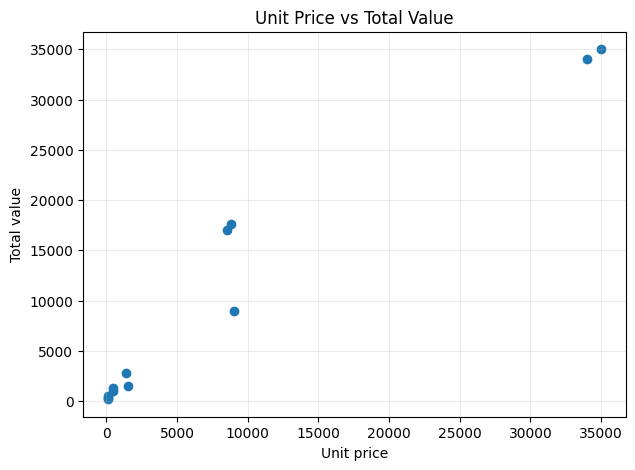

In [34]:
import matplotlib.pyplot as plt

plot_df = df.select(
    "unit_price",
    "total_value"
).toPandas()

plt.figure(figsize=(7, 5))
plt.scatter(
    plot_df["unit_price"],
    plot_df["total_value"]
)
plt.xlabel("Unit price")
plt.ylabel("Total value")
plt.title("Unit Price vs Total Value")
plt.grid(True, alpha=0.25)
plt.show()

# **Part 14 — Top-N and Group → Aggregate → Rank**

## **Step 14.1 — Top 5 highest-value transactions**

In [35]:
top5 = (
    df
    .orderBy(F.desc("total_value"))
    .select(
        "order_id",
        "city",
        "product",
        "total_value"
    )
)

top5.show(5)

+--------+---------+-------+-----------+
|order_id|     city|product|total_value|
+--------+---------+-------+-----------+
|    1001|  Bangkok| Laptop|    35000.0|
|    1003|ChiangMai| Laptop|    34000.0|
|    1012|ChiangMai|Monitor|    17600.0|
|    1008|  Bangkok|Monitor|    17000.0|
|    1007|   Phuket|Monitor|     9000.0|
+--------+---------+-------+-----------+
only showing top 5 rows


## **Step 14.2 — Rank product categories by total revenue**

In [36]:
category_rank = (
    df
    .groupBy("category")
    .agg(
        F.sum("total_value").alias("total_sales")
    )
    .orderBy(F.desc("total_sales"))
)

category_rank.show()

+-----------+-----------+
|   category|total_sales|
+-----------+-----------+
|Electronics|   112600.0|
|Accessories|     6650.0|
|       Food|     1110.0|
+-----------+-----------+



# **Part 15 — Guided Coding Activity**

## **1–3. Group, calculate statistics, and sort by total sales**

In [37]:

category_stats = (
    df
    .groupBy("category")
    .agg(
        F.count("*").alias("transaction_count"),
        F.sum("total_value").alias("total_sales"),
        F.mean("total_value").alias("mean_order_value"),
        F.stddev_samp("total_value").alias("stddev_order"),
        F.min("total_value").alias("min_order"),
        F.max("total_value").alias("max_order")
    )
    .orderBy(F.desc("total_sales"))
)

category_stats.show()


+-----------+-----------------+-----------+----------------+------------------+---------+---------+
|   category|transaction_count|total_sales|mean_order_value|      stddev_order|min_order|max_order|
+-----------+-----------------+-----------+----------------+------------------+---------+---------+
|Electronics|                5|   112600.0|         22520.0|11456.526524213174|   9000.0|  35000.0|
|Accessories|                4|     6650.0|          1662.5| 786.7390503421915|   1000.0|   2800.0|
|       Food|                3|     1110.0|           370.0| 175.2141546793523|    200.0|    550.0|
+-----------+-----------------+-----------+----------------+------------------+---------+---------+



## **4. Identify the category with the highest revenue**

In [38]:

highest_revenue = category_stats.first()

print("Category with highest revenue:", highest_revenue["category"])
print("Total revenue:", highest_revenue["total_sales"])


Category with highest revenue: Electronics
Total revenue: 112600.0


## **5. Identify the category with the largest variability**

In [39]:

largest_variability = (
    category_stats
    .orderBy(F.desc("stddev_order"))
    .first()
)

print("Category with largest variability:", largest_variability["category"])
print("Standard deviation:", largest_variability["stddev_order"])


Category with largest variability: Electronics
Standard deviation: 11456.526524213174


## **6. Interpretation **

The category with the highest total sales generates the most revenue among all categories, indicating that it contributes the largest amount to overall sales. The category with the highest standard deviation has the largest variability in order values, meaning its transaction amounts are more spread out compared to other categories. These results help identify the strongest revenue-generating category and the category with the most inconsistent order values.

# **Part 16 — Correlation Activity**

## **1.  Calculate correlation between quantity and total_value.**

In [40]:
corr_quantity = df.stat.corr(
    "quantity",
    "total_value"
)

print("Correlation(quantity, total_value):", corr_quantity)

Correlation(quantity, total_value): -0.5163637441860754


## **2.  Calculate correlation between unit_price and total_value.**

In [41]:
corr_price = df.stat.corr(
    "unit_price",
    "total_value"
)

print("Correlation(unit_price, total_value):", corr_price)

Correlation(unit_price, total_value): 0.9683239968895149


## **3.  Compare the direction and magnitude of the two coefficients.**

In [42]:
print("Quantity vs Total Value:", corr_quantity)
print("Unit Price vs Total Value:", corr_price)

Quantity vs Total Value: -0.5163637441860754
Unit Price vs Total Value: 0.9683239968895149


- Positive correlation means that when one variable increases, the other tends to increase.
- Negative correlation means that when one variable increases, the other tends to decrease.
- A correlation closer to +1 or -1 indicates a stronger linear relationship.
- A correlation closer to 0 indicates a weaker linear relationship.

## **4.  Explain why neither coefficient proves causation.**

Correlation does not prove causation because two variables may be related without one directly causing the other. Other factors may influence both variables, and correlation only measures the strength and direction of their linear relationship.

## **5.  Name at least one additional variable that could influence total order value.**

Discount: Discounts can reduce the final transaction value.



Product category: Different categories may have different price ranges.



Customer type: Different customers may purchase different quantities or products.

# **Part 17 — Mini Coding Challenges**

## **A — Find the city with the highest average order value**

In [43]:
# Calculate average order value by city

city_avg = (
    df
    .groupBy("city")
    .agg(
        F.mean("total_value").alias("average_order_value")
    )
    .orderBy(F.desc("average_order_value"))
)

city_avg.show()

# Find the city with the highest average order value
highest_city = city_avg.first()

print("City with highest average order value:",
      highest_city["city"])

print("Average order value:",
      highest_city["average_order_value"])

+---------+-------------------+
|     city|average_order_value|
+---------+-------------------+
|ChiangMai|            13287.5|
|  Bangkok|            11010.0|
|   Phuket| 4053.3333333333335|
+---------+-------------------+

City with highest average order value: ChiangMai
Average order value: 13287.5


## **D — Find the Top 3 products by aggregated revenue**

In [44]:
# Calculate total revenue for each product

top_products = (
    df
    .groupBy("product")
    .agg(
        F.sum("total_value").alias("total_revenue")
    )
    .orderBy(F.desc("total_revenue"))
    .limit(3)
)

top_products.show()

+--------+-------------+
| product|total_revenue|
+--------+-------------+
|  Laptop|      69000.0|
| Monitor|      43600.0|
|Keyboard|       4300.0|
+--------+-------------+

